In [2]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_rel, t

# --------------------------------------------------
# Load subject-level data
# --------------------------------------------------

df = pd.read_csv("C:/Users/user/Downloads/t test data.csv")

# Columns:
# Subject
# Engaged_mean
# Disengaged_mean

# --------------------------------------------------
# Descriptive statistics
# --------------------------------------------------

eng_mean = df["Engaged_mean"].mean()
eng_sd = df["Engaged_mean"].std(ddof=1)

dis_mean = df["Disengaged_mean"].mean()
dis_sd = df["Disengaged_mean"].std(ddof=1)

# --------------------------------------------------
# Difference
# --------------------------------------------------

df["Difference"] = (
    df["Engaged_mean"] -
    df["Disengaged_mean"]
)

mean_diff = df["Difference"].mean()
sd_diff = df["Difference"].std(ddof=1)

# --------------------------------------------------
# Paired t-test
# --------------------------------------------------

t_stat, p_value = ttest_rel(
    df["Engaged_mean"],
    df["Disengaged_mean"]
)

# --------------------------------------------------
# 95% Confidence Interval
# --------------------------------------------------

n = len(df)

se = sd_diff / np.sqrt(n)

t_critical = t.ppf(
    0.975,
    df=n-1
)

ci_lower = mean_diff - t_critical * se
ci_upper = mean_diff + t_critical * se

# --------------------------------------------------
# Cohen's dz
# --------------------------------------------------

cohens_dz = mean_diff / sd_diff

# --------------------------------------------------
# Print results
# --------------------------------------------------

print("\nDESCRIPTIVE STATISTICS")
print("----------------------")

print(
    f"Engaged: "
    f"{eng_mean:.2f} ± {eng_sd:.2f}"
)

print(
    f"Disengaged: "
    f"{dis_mean:.2f} ± {dis_sd:.2f}"
)

print("\nPAIRED T-TEST")
print("-------------")

print(f"n = {n}")
print(f"Mean difference = {mean_diff:.2f}")
print(f"t({n-1}) = {t_stat:.2f}")
print(f"p = {p_value:.6g}")

print(
    f"95% CI = "
    f"[{ci_lower:.2f}, {ci_upper:.2f}]"
)

print(f"Cohen's dz = {cohens_dz:.2f}")


DESCRIPTIVE STATISTICS
----------------------
Engaged: 3.95 ± 0.51
Disengaged: 3.06 ± 0.71

PAIRED T-TEST
-------------
n = 41
Mean difference = 0.89
t(40) = 7.39
p = 5.43998e-09
95% CI = [0.64, 1.13]
Cohen's dz = 1.15


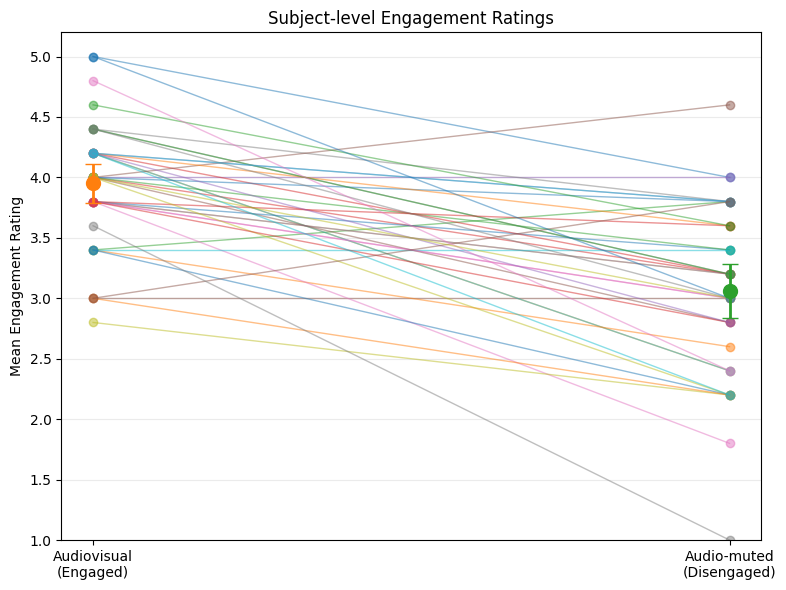

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

# Load data
df = pd.read_csv("C:/Users/user/Downloads/t test data.csv")

eng = df["Engaged_mean"].values
dis = df["Disengaged_mean"].values

# Paired t-test
t_stat, p_value = ttest_rel(eng, dis)

# Means
mean_eng = np.mean(eng)
mean_dis = np.mean(dis)

# Standard error
se_eng = np.std(eng, ddof=1) / np.sqrt(len(eng))
se_dis = np.std(dis, ddof=1) / np.sqrt(len(dis))

# 95% CI
from scipy.stats import t

critical = t.ppf(0.975, len(eng)-1)

ci_eng = critical * se_eng
ci_dis = critical * se_dis

# ------------------------------------------------
# Plot
# ------------------------------------------------
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

# Individual paired observations
for i in range(len(df)):
    plt.plot(
        [1, 2],
        [eng[i], dis[i]],
        marker='o',
        linewidth=1,
        alpha=0.5
    )

# Group means
plt.errorbar(
    1,
    mean_eng,
    yerr=ci_eng,
    fmt='o',
    markersize=10,
    capsize=6,
    linewidth=2,
    label='Mean ± 95% CI'
)

plt.errorbar(
    2,
    mean_dis,
    yerr=ci_dis,
    fmt='o',
    markersize=10,
    capsize=6,
    linewidth=2
)

# Labels
plt.xticks(
    [1, 2],
    ["Audiovisual\n(Engaged)", "Audio-muted\n(Disengaged)"]
)

plt.ylabel("Mean Engagement Rating")
plt.title("Subject-level Engagement Ratings")

plt.ylim(1, 5.2)

# Statistical result
#plt.text(
 #   1.5,
  #  5.05,
   # f"Paired t-test: t(40) = {t_stat:.2f}, p < 0.001",
    #ha='center',
    #fontsize=11
#)

plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.savefig("E:/My Research/PHD Thesis/t test.png")
plt.show()

In [7]:
plt.savefig("E:/My Research/PHD Thesis/t test.png")

<Figure size 640x480 with 0 Axes>

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_rel, wilcoxon

# Load data
df = pd.read_csv("C:/Users/user/Downloads/t test data.csv")

eng = df["Engaged_mean"].dropna()
dis = df["Disengaged_mean"].dropna()

# Ensure paired observations are complete
paired = df[["Engaged_mean", "Disengaged_mean"]].dropna()
eng = paired["Engaged_mean"].to_numpy()
dis = paired["Disengaged_mean"].to_numpy()

# Descriptive statistics
print("Number of participants:", len(eng))
print("Engaged condition mean:", np.mean(eng))
print("Engaged condition SD:", np.std(eng, ddof=1))
print("Disengaged condition mean:", np.mean(dis))
print("Disengaged condition SD:", np.std(dis, ddof=1))

# Existing paired t-test
t_stat, t_p = ttest_rel(eng, dis)
print("\nPaired t-test")
print("t-statistic:", t_stat)
print("p-value:", t_p)

# Additional nonparametric paired test
w_stat, w_p = wilcoxon(
    eng, dis,
    alternative="two-sided",
    zero_method="wilcox"
)
print("\nWilcoxon signed-rank test")
print("W-statistic:", w_stat)
print("p-value:", w_p)

# Median ratings
print("\nEngaged median:", np.median(eng))
print("Disengaged median:", np.median(dis))

Number of participants: 41
Engaged condition mean: 3.951219512195122
Engaged condition SD: 0.5055303903918696
Disengaged condition mean: 3.0634146341463415
Disengaged condition SD: 0.7077273830935805

Paired t-test
t-statistic: 7.3877606941357925
p-value: 5.4399837251950504e-09

Wilcoxon signed-rank test
W-statistic: 28.5
p-value: 6.904833101672937e-07

Engaged median: 4.0
Disengaged median: 3.2
